# OSMOS Dynamic Classification Model — Fixed Version

This notebook fixes the classification/RFM problems before updating the Streamlit interface.

## Main fixes
1. RFM-ES is calculated before creating `X` and `y`.
2. The 3-expert Group AHP logic is kept.
3. `entity_type` stays as `"Prospect"` / `"Client"` instead of `0/1`.
4. `dynamic_class` is regenerated after RFM-ES so labels are coherent.
5. Manual tests use clean examples and the final best model.
6. The exported artifact includes metadata for the Streamlit app.

**Important for Streamlit:** if `artifact["entity_type_format"] == "string"`, the app must not convert `Prospect` / `Client` to `0/1`.

In [1]:
# ============================================================
# 1. Imports and configuration
# ============================================================

import os
import json
import time
import joblib
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
RUN_ADVANCED_MODELS = False
SELECTION_METRIC = "f1_macro"
REGENERATE_DYNAMIC_CLASS = True

print("Notebook initialized.")


Notebook initialized.


In [2]:
# ============================================================
# 2. Load OSMOS data robustly
# ============================================================

DATA_PATHS = [
    Path("osmos_digital_twin_data.xlsx"),
    Path("OSMOS_Digital_Twin_Simulation_Data.xlsx"),
    Path("osmos_simulation_data.xlsx"),
    Path("base models/RFM/osmos_simulation_data.xlsx"),
    Path("base models/osmos_simulation_data.xlsx"),
    Path(r"D:\EMSI\PFA SUMMER\base models\CRM\digital_twin_dataset.xlsx"),
]

def find_existing_data_path(paths):
    for p in paths:
        if p.exists():
            return p
    return None

def normalize_entity_type(series):
    def _norm(x):
        if pd.isna(x):
            return "Prospect"
        sx = str(x).strip().lower()
        if sx in ["1", "client", "clients"]:
            return "Client"
        if sx in ["0", "prospect", "prospects"]:
            return "Prospect"
        return str(x).strip().title()
    return series.apply(_norm)

def load_osmos_data(data_paths):
    excel_path = find_existing_data_path(data_paths)
    if excel_path is None:
        raise FileNotFoundError(
            "No OSMOS Excel data file found. Put osmos_digital_twin_data.xlsx or "
            "OSMOS_Digital_Twin_Simulation_Data.xlsx in the notebook folder."
        )

    print("Using data file:", excel_path)
    xls = pd.ExcelFile(excel_path)
    print("Sheets:", xls.sheet_names)

    if "Digital_Twins" not in xls.sheet_names:
        raise ValueError("The Excel file must contain a 'Digital_Twins' sheet.")

    snapshots = pd.read_excel(excel_path, sheet_name="Digital_Twins")

    if "Customers" in xls.sheet_names:
        profiles = pd.read_excel(excel_path, sheet_name="Customers")
        df = snapshots.merge(
            profiles,
            on=["entity_id", "entity_type"],
            how="left",
            suffixes=("", "_profile")
        )
    else:
        df = snapshots.copy()

    df = df.loc[:, ~df.columns.duplicated()].copy()

    if "entity_type" not in df.columns:
        raise ValueError("Missing required column: entity_type")

    df["entity_type"] = normalize_entity_type(df["entity_type"])

    if "snapshot_date" in df.columns:
        df["snapshot_date"] = df["snapshot_date"].astype(str)
    if "created_at" in df.columns:
        df["created_at"] = df["created_at"].astype(str)

    return df, excel_path

df, DATA_FILE_USED = load_osmos_data(DATA_PATHS)

print("Loaded shape:", df.shape)
display(df.head())


Using data file: osmos_digital_twin_data.xlsx


Sheets: ['Digital_Twins', 'Event_History']


Loaded shape: (1506, 72)


,entity_id,entity_type,snapshot_date,basic_profile_score,behavioral_engagement_score,predictive_value_score,decision_priority_score,recency_days,visits_30d,product_views_30d,cart_additions_30d,purchases_90d,total_spent_90d_mad,avg_order_value_mad,email_open_rate,email_click_rate,complaint_count_90d,review_score_avg,social_mentions_30d,social_sentiment_avg,rfm_score,conversion_probability,churn_risk_score,dynamic_class,recommended_action,created_at,region,source_channel,segment,persona,age_group,preferred_device,preferred_category,marketing_consent,price_sensitivity,income_power_score,initial_interest_score,age,sex,email,customer_type,household_size,phone_number,company_name,job_title,city,address,original_entity_type,converted_at,conversion_event_id,completed_client_profile,predicted_clv_amount_mad,predicted_clv_score,predicted_clv_segment,clv_model_name,clv_last_updated,R_raw,F_raw,M_raw,E_raw,S_raw,rfm_recency_score,rfm_frequency_score,rfm_monetary_score,rfm_engagement_score,rfm_sentiment_score,rfm_score_raw_1_to_5,ahp_weight_R,ahp_weight_F,ahp_weight_M,ahp_weight_E,ahp_weight_S
0,P00001,Prospect,2026-06-17,0.458,0.135000,0.1560,0.131000,27,3,12,0,0,0.00,0.000000,0.378,0.059,0,NaN,0,0.367,0.461431,0.119,0.000,Cold Prospect,Continue awareness campaign,2025-09-12,Fès-Meknès,Facebook Ads,Student,Price Sensitive,18-24,Desktop,Electronics,True,0.957,0.285,0.135,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27,15,0.000000,0.165346,0.6835,3,3,1,2,3,2.845724,0.350950,0.320362,0.000000,0.154276,0.174412
1,C00002,Client,2026-06-17,0.734,0.204000,0.4000,0.359000,30,1,3,0,3,2974.47,991.490000,0.328,0.039,1,2.78,1,0.505,0.627302,1.000,0.396,Active Client,Send personalized product recommendation,2025-10-20,Laâyoune-Sakia El Hamra,Google Search,Student,B2B Decision Maker,35-44,Desktop,Fashion,True,0.367,0.736,0.115,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30,3,991.490000,0.121087,0.7525,3,1,5,1,4,3.509209,0.188547,0.172114,0.462752,0.082885,0.093703
2,C00003,Client,2026-06-17,0.440,0.826267,0.9264,0.706073,0,17,74,13,7,23983.08,3426.154286,0.478,0.114,0,3.97,2,0.782,0.913943,1.000,0.000,VIP Client,Send VIP loyalty reward,2026-05-14,Rabat-Salé-Kénitra,Marketplace App,B2C,Quality Seeker,35-44,Mobile,Home,True,0.792,0.138,0.613,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.504065,5.155684,Low Future Value,Hist Gradient Boosting,2026-07-02 12:26:08,0,7,3426.154286,0.363803,0.8910,5,3,5,5,5,4.655772,0.188547,0.172114,0.462752,0.082885,0.093703
3,P00004,Prospect,2026-06-17,0.525,1.000000,0.7260,0.808000,21,26,96,12,0,0.00,0.000000,0.352,0.054,0,NaN,3,0.820,0.824525,0.794,0.000,Hot Prospect,Send limited-time personalized offer,2025-09-02,Marrakech-Safi,Organic SEO,Family,Trend Follower,18-24,Desktop,Fashion,True,0.472,0.197,0.920,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21,134,0.000000,0.353972,0.9100,3,5,1,5,5,4.298100,0.350950,0.320362,0.000000,0.154276,0.174412
4,C00005,Client,2026-06-17,0.553,0.341000,0.3520,0.421000,67,7,28,2,4,1747.41,436.850000,0.517,0.091,0,4.24,2,0.053,0.411932,1.000,0.510,Active Client,Send personalized product recommendation,2025-09-27,Casablanca-Settat,Referral,B2C,Quality Seeker,25-34,Mobile,Electronics,True,0.601,0.353,0.137,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,67,4,436.850000,0.257642,0.5265,1,1,4,3,2,2.647727,0.188547,0.172114,0.462752,0.082885,0.093703


In [3]:
# ============================================================
# 3. Schema safety and defaults
# ============================================================

DEFAULTS = {
    "entity_id": None,
    "entity_type": "Prospect",
    "region": "Unknown",
    "source_channel": "Unknown",
    "segment": "Unknown",
    "persona": "Unknown",
    "age_group": "Unknown",
    "preferred_device": "Unknown",
    "preferred_category": "Unknown",
    "marketing_consent": True,
    "price_sensitivity": 0.5,
    "income_power_score": 0.5,
    "initial_interest_score": 0.5,

    "recency_days": 30.0,
    "visits_30d": 0.0,
    "product_views_30d": 0.0,
    "cart_additions_30d": 0.0,
    "purchases_90d": 0.0,
    "total_spent_90d_mad": 0.0,
    "avg_order_value_mad": 0.0,
    "email_open_rate": 0.0,
    "email_click_rate": 0.0,
    "complaint_count_90d": 0.0,
    "review_score_avg": np.nan,
    "social_mentions_30d": 0.0,
    "social_sentiment_avg": 0.5,

    "basic_profile_score": 0.5,
    "rfm_score": 0.0,
    "conversion_probability": 0.0,
    "churn_risk_score": 0.0,
    "behavioral_engagement_score": 0.0,
    "predictive_value_score": 0.0,
    "decision_priority_score": 0.0,
}

CATEGORICAL_BASE_COLS = [
    "entity_type",
    "region",
    "source_channel",
    "segment",
    "persona",
    "age_group",
    "preferred_device",
    "preferred_category",
    "marketing_consent",
]

NUMERIC_BASE_COLS = [
    col for col in DEFAULTS.keys()
    if col not in CATEGORICAL_BASE_COLS and col != "entity_id"
]

def ensure_schema(df):
    df = df.copy()

    for col, default in DEFAULTS.items():
        if col not in df.columns:
            df[col] = default

    df["entity_type"] = normalize_entity_type(df["entity_type"])

    for col in CATEGORICAL_BASE_COLS:
        if col in df.columns:
            df[col] = df[col].fillna("Unknown").astype(str)

    for col in NUMERIC_BASE_COLS:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    return df

df = ensure_schema(df)

print("Schema checked.")
print(df["entity_type"].value_counts())


Schema checked.
entity_type
Prospect    819
Client      687
Name: count, dtype: int64


In [4]:
# ============================================================
# 4. 3-expert AHP Group Decision Making
# ============================================================

def calculate_ahp_weights(pairwise_matrix, criteria):
    pairwise_matrix = np.array(pairwise_matrix, dtype=float)
    n = pairwise_matrix.shape[0]

    eigenvalues, eigenvectors = np.linalg.eig(pairwise_matrix)
    max_index = np.argmax(eigenvalues.real)
    max_eigenvalue = float(eigenvalues.real[max_index])

    principal_eigenvector = np.abs(eigenvectors[:, max_index].real)
    weights = principal_eigenvector / principal_eigenvector.sum()

    CI = (max_eigenvalue - n) / (n - 1)
    RI_dict = {
        1: 0.00,
        2: 0.00,
        3: 0.58,
        4: 0.90,
        5: 1.12,
        6: 1.24,
        7: 1.32,
        8: 1.41,
        9: 1.45,
        10: 1.49,
    }
    RI = RI_dict.get(n, 1.49)
    CR = 0.0 if RI == 0 else CI / RI

    weights_dict = {criteria[i]: float(weights[i]) for i in range(n)}
    return weights_dict, float(CI), float(CR), float(max_eigenvalue)

def aggregate_expert_matrices_geometric_mean(expert_matrices):
    matrices = np.array(expert_matrices, dtype=float)

    if np.any(matrices <= 0):
        raise ValueError("AHP matrices must contain strictly positive values.")

    aggregated_matrix = np.exp(np.mean(np.log(matrices), axis=0))

    n = aggregated_matrix.shape[0]
    for i in range(n):
        aggregated_matrix[i, i] = 1.0
        for j in range(i + 1, n):
            aggregated_matrix[j, i] = 1.0 / aggregated_matrix[i, j]

    return aggregated_matrix

def get_group_ahp_result():
    criteria = ["R", "F", "M", "E", "S"]

    expert_1_matrix = [
        [1,   1,   1/3, 3,   2],
        [1,   1,   1/3, 2,   2],
        [3,   3,   1,   5,   4],
        [1/3, 1/2, 1/5, 1,   1],
        [1/2, 1/2, 1/4, 1,   1],
    ]

    expert_2_matrix = [
        [1,   2,   1/4, 3,   2],
        [1/2, 1,   1/3, 2,   2],
        [4,   3,   1,   5,   4],
        [1/3, 1/2, 1/5, 1,   1],
        [1/2, 1/2, 1/4, 1,   1],
    ]

    expert_3_matrix = [
        [1,   1,   1/2, 2,   2],
        [1,   1,   1/3, 2,   3],
        [2,   3,   1,   4,   4],
        [1/2, 1/2, 1/4, 1,   1],
        [1/2, 1/3, 1/4, 1,   1],
    ]

    expert_matrices = [expert_1_matrix, expert_2_matrix, expert_3_matrix]
    aggregated_matrix = aggregate_expert_matrices_geometric_mean(expert_matrices)

    final_weights, final_CI, final_CR, lambda_max = calculate_ahp_weights(
        aggregated_matrix,
        criteria
    )

    return {
        "criteria": criteria,
        "expert_matrices": expert_matrices,
        "aggregated_matrix": aggregated_matrix,
        "weights": final_weights,
        "CI": final_CI,
        "CR": final_CR,
        "lambda_max": lambda_max,
        "expert_count": len(expert_matrices),
    }

ahp_result = get_group_ahp_result()

print("Group AHP weights:")
print(ahp_result["weights"])
print("CI:", round(ahp_result["CI"], 4))
print("CR:", round(ahp_result["CR"], 4))
print("Consistent:", ahp_result["CR"] <= 0.10)

display(pd.DataFrame(ahp_result["aggregated_matrix"], index=ahp_result["criteria"], columns=ahp_result["criteria"]))


Group AHP weights:
{'R': 0.19419566392200824, 'F': 0.1708562140395259, 'M': 0.4561846942497113, 'E': 0.08660807134788479, 'S': 0.09215535644086972}
CI: 0.0102
CR: 0.0091
Consistent: True


,R,F,M,E,S
R,1.000000,1.259921,0.346681,2.620741,2.000000
F,0.793701,1.000000,0.333333,2.000000,2.289428
M,2.884499,3.000000,1.000000,4.641589,4.000000
E,0.381571,0.500000,0.215443,1.000000,1.000000
S,0.500000,0.436790,0.250000,1.000000,1.000000


In [5]:
# ============================================================
# 5. Calculate RFM-ES score
# ============================================================

def quintile_score(series, reverse=False):
    series = pd.to_numeric(series, errors="coerce").fillna(0.0)

    if series.nunique() <= 1:
        score = pd.Series(3, index=series.index)
    else:
        try:
            score = pd.qcut(
                series.rank(method="first"),
                q=5,
                labels=[1, 2, 3, 4, 5]
            ).astype(int)
        except Exception:
            score = pd.Series(3, index=series.index)

    if reverse:
        score = 6 - score

    return score

def calculate_rfm_es(df):
    df = ensure_schema(df)

    numeric_cols_rfm = [
        "recency_days",
        "visits_30d",
        "product_views_30d",
        "cart_additions_30d",
        "purchases_90d",
        "total_spent_90d_mad",
        "avg_order_value_mad",
        "email_open_rate",
        "email_click_rate",
        "social_sentiment_avg",
    ]

    for col in numeric_cols_rfm:
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0.0)

    is_client = df["entity_type"].astype(str).str.lower().isin(["client", "1"])

    df["R_raw"] = df["recency_days"]

    df["F_raw"] = np.where(
        is_client,
        df["purchases_90d"],
        df["visits_30d"] + df["product_views_30d"] + df["cart_additions_30d"]
    )

    df["M_raw"] = np.where(
        is_client,
        df["avg_order_value_mad"],
        0.0
    )

    mask_client_missing_aov = (
        is_client
        & (df["avg_order_value_mad"] == 0)
        & (df["purchases_90d"] > 0)
    )

    df.loc[mask_client_missing_aov, "M_raw"] = (
        df.loc[mask_client_missing_aov, "total_spent_90d_mad"]
        / df.loc[mask_client_missing_aov, "purchases_90d"]
    )

    max_product_views = df["product_views_30d"].max()
    normalized_product_views = (
        pd.Series(0.0, index=df.index)
        if max_product_views == 0
        else df["product_views_30d"] / max_product_views
    )

    df["E_raw"] = (
        0.40 * df["email_click_rate"]
        + 0.30 * df["email_open_rate"]
        + 0.30 * normalized_product_views
    )

    if df["social_sentiment_avg"].min() < 0:
        df["S_raw"] = (df["social_sentiment_avg"] + 1) / 2
    else:
        df["S_raw"] = df["social_sentiment_avg"]

    df["S_raw"] = df["S_raw"].clip(0.0, 1.0)

    df["rfm_recency_score"] = quintile_score(df["R_raw"], reverse=True)
    df["rfm_frequency_score"] = quintile_score(df["F_raw"])
    df["rfm_monetary_score"] = quintile_score(df["M_raw"])
    df["rfm_engagement_score"] = quintile_score(df["E_raw"])
    df["rfm_sentiment_score"] = quintile_score(df["S_raw"])

    ahp_result = get_group_ahp_result()
    client_ahp_weights = ahp_result["weights"]

    prospect_ahp_weights = {
        "R": client_ahp_weights["R"],
        "F": client_ahp_weights["F"],
        "E": client_ahp_weights["E"],
        "S": client_ahp_weights["S"],
    }

    total_prospect_weight = sum(prospect_ahp_weights.values())
    prospect_ahp_weights = {
        key: value / total_prospect_weight
        for key, value in prospect_ahp_weights.items()
    }

    client_score = (
        client_ahp_weights["R"] * df["rfm_recency_score"]
        + client_ahp_weights["F"] * df["rfm_frequency_score"]
        + client_ahp_weights["M"] * df["rfm_monetary_score"]
        + client_ahp_weights["E"] * df["rfm_engagement_score"]
        + client_ahp_weights["S"] * df["rfm_sentiment_score"]
    )

    prospect_score = (
        prospect_ahp_weights["R"] * df["rfm_recency_score"]
        + prospect_ahp_weights["F"] * df["rfm_frequency_score"]
        + prospect_ahp_weights["E"] * df["rfm_engagement_score"]
        + prospect_ahp_weights["S"] * df["rfm_sentiment_score"]
    )

    df["rfm_score_raw_1_to_5"] = np.where(is_client, client_score, prospect_score)
    df["rfm_score"] = ((df["rfm_score_raw_1_to_5"] - 1) / 4).clip(0.0, 1.0)

    df["ahp_weight_R"] = np.where(is_client, client_ahp_weights["R"], prospect_ahp_weights["R"])
    df["ahp_weight_F"] = np.where(is_client, client_ahp_weights["F"], prospect_ahp_weights["F"])
    df["ahp_weight_M"] = np.where(is_client, client_ahp_weights["M"], 0.0)
    df["ahp_weight_E"] = np.where(is_client, client_ahp_weights["E"], prospect_ahp_weights["E"])
    df["ahp_weight_S"] = np.where(is_client, client_ahp_weights["S"], prospect_ahp_weights["S"])
    df["ahp_group_CR"] = ahp_result["CR"]
    df["ahp_group_CI"] = ahp_result["CI"]
    df["ahp_expert_count"] = ahp_result["expert_count"]

    return df

df = calculate_rfm_es(df)

print("RFM-ES calculated.")
display(df[["entity_id", "entity_type", "R_raw", "F_raw", "M_raw", "E_raw", "S_raw", "rfm_score"]].head())
display(df.groupby("entity_type")["rfm_score"].describe())


RFM-ES calculated.


,entity_id,entity_type,R_raw,F_raw,M_raw,E_raw,S_raw,rfm_score
0,P00001,Prospect,27,15,0.000000,0.165346,0.6835,0.460185
1,C00002,Client,30,3,991.490000,0.121087,0.7525,0.622399
2,C00003,Client,0,7,3426.154286,0.363803,0.8910,0.914572
3,P00004,Prospect,21,134,0.000000,0.353972,0.9100,0.821451
4,C00005,Client,67,4,436.850000,0.257642,0.5265,0.408481


,count,mean,std,min,25%,50%,75%,max
entity_type,,,,,,,,
Client,687.0,0.577954,0.158383,0.0,0.503778,0.595758,0.688719,0.914572
Prospect,819.0,0.586225,0.210555,0.0,0.420912,0.607631,0.746365,1.000000


In [6]:
# ============================================================
# 6. Recalculate derived scores
# ============================================================

def update_derived_scores(df):
    df = df.copy()

    for col, default in [
        ("visits_30d", 0.0),
        ("product_views_30d", 0.0),
        ("cart_additions_30d", 0.0),
        ("email_click_rate", 0.0),
        ("conversion_probability", 0.0),
        ("rfm_score", 0.0),
        ("social_sentiment_avg", 0.5),
        ("churn_risk_score", 0.0),
    ]:
        if col not in df.columns:
            df[col] = default
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(default)

    df["behavioral_engagement_score"] = np.clip(
        (df["visits_30d"] / 30.0) * 0.25
        + (df["product_views_30d"] / 80.0) * 0.30
        + (df["cart_additions_30d"] / 10.0) * 0.30
        + df["email_click_rate"] * 0.15,
        0.0,
        1.0
    )

    df["predictive_value_score"] = np.clip(
        df["conversion_probability"] * 0.50
        + df["rfm_score"] * 0.30
        + df["social_sentiment_avg"] * 0.20,
        0.0,
        1.0
    )

    df["decision_priority_score"] = np.clip(
        df["behavioral_engagement_score"] * 0.35
        + df["predictive_value_score"] * 0.45
        + df["churn_risk_score"] * 0.20,
        0.0,
        1.0
    )

    return df

df = update_derived_scores(df)

display(df[[
    "entity_id",
    "entity_type",
    "rfm_score",
    "behavioral_engagement_score",
    "predictive_value_score",
    "decision_priority_score"
]].head())


,entity_id,entity_type,rfm_score,behavioral_engagement_score,predictive_value_score,decision_priority_score
0,P00001,Prospect,0.460185,0.078850,0.270955,0.149527
1,C00002,Client,0.622399,0.025433,0.787720,0.442576
2,C00003,Client,0.914572,0.826267,0.930772,0.708041
3,P00004,Prospect,0.821451,0.944767,0.807435,0.694014
4,C00005,Client,0.408481,0.236983,0.633144,0.469859


In [7]:
# ============================================================
# 7. Regenerate / validate dynamic_class labels
# ============================================================

def assign_dynamic_classes(df):
    df = df.copy()
    df["entity_type"] = normalize_entity_type(df["entity_type"])

    numeric_for_rules = [
        "rfm_score",
        "behavioral_engagement_score",
        "conversion_probability",
        "decision_priority_score",
        "churn_risk_score",
        "recency_days",
        "visits_30d",
        "product_views_30d",
        "cart_additions_30d",
        "purchases_90d",
        "total_spent_90d_mad",
        "avg_order_value_mad",
        "complaint_count_90d",
        "social_sentiment_avg",
    ]

    for col in numeric_for_rules:
        if col not in df.columns:
            df[col] = 0.0
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0.0)

    if "dynamic_class" in df.columns:
        df["dynamic_class_original"] = df["dynamic_class"]
    else:
        df["dynamic_class_original"] = None

    is_prospect = df["entity_type"].str.lower().eq("prospect")
    is_client = df["entity_type"].str.lower().eq("client")

    df["dynamic_class"] = None

    prospects = df[is_prospect].copy()

    if len(prospects) > 0:
        recency_rank = prospects["recency_days"].rank(pct=True)

        lead_score = (
            0.40 * prospects["conversion_probability"]
            + 0.30 * prospects["behavioral_engagement_score"]
            + 0.20 * prospects["rfm_score"]
            + 0.10 * (1.0 - recency_rank)
        )

        prospect_labels = pd.qcut(
            lead_score.rank(method="first"),
            q=[0.00, 0.33, 0.70, 1.00],
            labels=["Cold Prospect", "Warm Prospect", "Hot Prospect"]
        ).astype(str)

        df.loc[prospects.index, "dynamic_class"] = prospect_labels.values

    clients = df[is_client].copy()

    if len(clients) > 0:
        def Q(col, q):
            return clients[col].quantile(q)

        df.loc[is_client, "dynamic_class"] = "Active Client"

        dormant_mask = (
            is_client
            & (df["recency_days"] >= Q("recency_days", 0.75))
            & (df["visits_30d"] <= Q("visits_30d", 0.40))
            & (df["product_views_30d"] <= Q("product_views_30d", 0.40))
            & (df["purchases_90d"] <= Q("purchases_90d", 0.60))
        )

        churn_risk_mask = (
            is_client
            & (
                (df["churn_risk_score"] >= Q("churn_risk_score", 0.75))
                | (df["complaint_count_90d"] >= 2)
                | (
                    (df["recency_days"] >= Q("recency_days", 0.75))
                    & (df["social_sentiment_avg"] <= Q("social_sentiment_avg", 0.25))
                    & (df["behavioral_engagement_score"] <= Q("behavioral_engagement_score", 0.30))
                )
            )
        )

        vip_mask = (
            is_client
            & (df["rfm_score"] >= Q("rfm_score", 0.80))
            & (df["total_spent_90d_mad"] >= Q("total_spent_90d_mad", 0.75))
            & (df["purchases_90d"] >= Q("purchases_90d", 0.70))
            & (df["churn_risk_score"] <= Q("churn_risk_score", 0.60))
        )

        loyal_mask = (
            is_client
            & (df["rfm_score"] >= Q("rfm_score", 0.60))
            & (df["purchases_90d"] >= Q("purchases_90d", 0.60))
            & (df["churn_risk_score"] < Q("churn_risk_score", 0.75))
        )

        new_client_mask = (
            is_client
            & (df["purchases_90d"] <= 2)
            & (df["total_spent_90d_mad"] > 0)
            & (df["recency_days"] <= 45)
        )

        df.loc[vip_mask, "dynamic_class"] = "VIP Client"
        df.loc[loyal_mask & ~vip_mask, "dynamic_class"] = "Loyal Client"
        df.loc[churn_risk_mask & ~(vip_mask | loyal_mask), "dynamic_class"] = "Churn Risk Client"
        df.loc[dormant_mask & ~(vip_mask | loyal_mask), "dynamic_class"] = "Dormant Client"
        df.loc[
            new_client_mask & ~(vip_mask | loyal_mask | dormant_mask | churn_risk_mask),
            "dynamic_class"
        ] = "New Client"

    return df

if REGENERATE_DYNAMIC_CLASS:
    df = assign_dynamic_classes(df)
    target_generation = "dynamic_class_regenerated_after_rfm_es"
else:
    target_generation = "dynamic_class_original_from_dataset"

print("Target generation:", target_generation)
print("\nNew class distribution:")
print(df["dynamic_class"].value_counts())

print("\nDistribution by entity type:")
display(pd.crosstab(df["entity_type"], df["dynamic_class"]))

if "dynamic_class_original" in df.columns:
    print("\nOriginal vs regenerated labels:")
    display(pd.crosstab(df["dynamic_class_original"], df["dynamic_class"]))


Target generation: dynamic_class_regenerated_after_rfm_es

New class distribution:
dynamic_class
Warm Prospect        303
Active Client        294
Cold Prospect        270
Hot Prospect         246
Churn Risk Client    142
Loyal Client         115
VIP Client            60
Dormant Client        38
New Client            38
Name: count, dtype: int64

Distribution by entity type:


dynamic_class,Active Client,Churn Risk Client,Cold Prospect,Dormant Client,Hot Prospect,Loyal Client,New Client,VIP Client,Warm Prospect
entity_type,,,,,,,,,
Client,294,142,0,38,0,115,38,60,0
Prospect,0,0,270,0,246,0,0,0,303



Original vs regenerated labels:


dynamic_class,Active Client,Churn Risk Client,Cold Prospect,Dormant Client,Hot Prospect,Loyal Client,New Client,VIP Client,Warm Prospect
dynamic_class_original,,,,,,,,,
Active Client,150,37,0,3,0,1,34,0,0
Churn Risk Client,0,90,0,31,0,0,0,0,0
Cold Prospect,0,0,159,0,0,0,0,0,34
Dormant Client,2,4,0,2,0,0,0,0,0
Hot Prospect,0,0,8,0,169,0,0,0,57
Loyal Client,122,10,0,0,0,56,3,3,0
New Client,6,1,0,2,0,0,1,0,0
VIP Client,14,0,0,0,0,58,0,57,0
Warm Prospect,0,0,103,0,77,0,0,0,212


In [8]:
# ============================================================
# 8. Create X and y AFTER RFM-ES + derived scores + labels
# ============================================================

TARGET = "dynamic_class"

profile_features = [
    "entity_type",
    "region",
    "source_channel",
    "segment",
    "persona",
    "age_group",
    "preferred_device",
    "preferred_category",
    "marketing_consent",
    "price_sensitivity",
    "income_power_score",
    "initial_interest_score",
]

behavior_features = [
    "recency_days",
    "visits_30d",
    "product_views_30d",
    "cart_additions_30d",
    "purchases_90d",
    "total_spent_90d_mad",
    "avg_order_value_mad",
    "email_open_rate",
    "email_click_rate",
    "complaint_count_90d",
    "review_score_avg",
    "social_mentions_30d",
    "social_sentiment_avg",
]

score_features = [
    "rfm_score",
    "conversion_probability",
    "churn_risk_score",
    "behavioral_engagement_score",
    "predictive_value_score",
    "decision_priority_score",
    "rfm_recency_score",
    "rfm_frequency_score",
    "rfm_monetary_score",
    "rfm_engagement_score",
    "rfm_sentiment_score",
]

feature_columns = [
    col for col in profile_features + behavior_features + score_features
    if col in df.columns
]

X = df[feature_columns].copy()
y = df[TARGET].copy()

categorical_cols = [
    col for col in [
        "entity_type",
        "region",
        "source_channel",
        "segment",
        "persona",
        "age_group",
        "preferred_device",
        "preferred_category",
        "marketing_consent",
    ]
    if col in X.columns
]

numerical_cols = [col for col in X.columns if col not in categorical_cols]

for col in categorical_cols:
    X[col] = X[col].fillna("Unknown").astype(str)

for col in numerical_cols:
    X[col] = pd.to_numeric(X[col], errors="coerce")

print("Feature count:", len(feature_columns))
print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)
print("\nTarget distribution:")
print(y.value_counts())


Feature count: 36
Categorical columns: ['entity_type', 'region', 'source_channel', 'segment', 'persona', 'age_group', 'preferred_device', 'preferred_category', 'marketing_consent']
Numerical columns: ['price_sensitivity', 'income_power_score', 'initial_interest_score', 'recency_days', 'visits_30d', 'product_views_30d', 'cart_additions_30d', 'purchases_90d', 'total_spent_90d_mad', 'avg_order_value_mad', 'email_open_rate', 'email_click_rate', 'complaint_count_90d', 'review_score_avg', 'social_mentions_30d', 'social_sentiment_avg', 'rfm_score', 'conversion_probability', 'churn_risk_score', 'behavioral_engagement_score', 'predictive_value_score', 'decision_priority_score', 'rfm_recency_score', 'rfm_frequency_score', 'rfm_monetary_score', 'rfm_engagement_score', 'rfm_sentiment_score']

Target distribution:
dynamic_class
Warm Prospect        303
Active Client        294
Cold Prospect        270
Hot Prospect         246
Churn Risk Client    142
Loyal Client         115
VIP Client            6

In [9]:
# ============================================================
# 9. Preprocessing pipeline and train/test split
# ============================================================

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols),
    ]
)

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

class_names = label_encoder.classes_

print("Encoded classes:")
for i, cls in enumerate(class_names):
    print(i, "->", cls)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_encoded
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Encoded classes:
0 -> Active Client
1 -> Churn Risk Client
2 -> Cold Prospect
3 -> Dormant Client
4 -> Hot Prospect
5 -> Loyal Client
6 -> New Client
7 -> VIP Client
8 -> Warm Prospect
Train shape: (1204, 36)
Test shape: (302, 36)


In [10]:
# ============================================================
# 10. Train and compare models
# ============================================================

from sklearn.utils.class_weight import compute_sample_weight

# Balanced sample weights improve minority classes such as Dormant Client and New Client.
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=120,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=120,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE,
    ),
}

# Models that benefit directly from sample_weight during .fit()
USE_SAMPLE_WEIGHT = {
    "Gradient Boosting": True,
    "Hist Gradient Boosting": True,
    "XGBoost": True,
    "LightGBM": True,
    "CatBoost": True,
}

if RUN_ADVANCED_MODELS:
    models["Hist Gradient Boosting"] = HistGradientBoostingClassifier(
        learning_rate=0.08,
        max_iter=200,
        random_state=RANDOM_STATE,
    )

    try:
        from xgboost import XGBClassifier
        models["XGBoost"] = XGBClassifier(
            n_estimators=250,
            learning_rate=0.05,
            max_depth=5,
            subsample=0.90,
            colsample_bytree=0.90,
            objective="multi:softprob",
            eval_metric="mlogloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    except ImportError:
        print("XGBoost is not installed. Install with: pip install xgboost")

    try:
        from lightgbm import LGBMClassifier
        models["LightGBM"] = LGBMClassifier(
            n_estimators=250,
            learning_rate=0.05,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbose=-1,
        )
    except ImportError:
        print("LightGBM is not installed. Install with: pip install lightgbm")

    try:
        from catboost import CatBoostClassifier
        models["CatBoost"] = CatBoostClassifier(
            iterations=250,
            learning_rate=0.05,
            depth=6,
            loss_function="MultiClass",
            verbose=False,
            random_state=RANDOM_STATE,
        )
    except ImportError:
        print("CatBoost is not installed. Install with: pip install catboost")

results = []
trained_models = {}

for model_name, classifier in models.items():
    print(f"\nTraining: {model_name}")

    pipeline_model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier),
    ])

    fit_kwargs = {}
    if USE_SAMPLE_WEIGHT.get(model_name, False):
        fit_kwargs["classifier__sample_weight"] = sample_weights

    start_time = time.time()
    pipeline_model.fit(X_train, y_train, **fit_kwargs)
    training_time = time.time() - start_time

    y_pred = pipeline_model.predict(X_test)

    results.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_test, y_pred, average="macro"),
        "f1_weighted": f1_score(y_test, y_pred, average="weighted"),
        "uses_balanced_sample_weight": USE_SAMPLE_WEIGHT.get(model_name, False),
        "training_time_seconds": training_time,
    })

    trained_models[model_name] = pipeline_model

results_df = pd.DataFrame(results).sort_values(by=SELECTION_METRIC, ascending=False).reset_index(drop=True)

display(results_df)

best_model_name = results_df.iloc[0]["model"]
best_model = trained_models[best_model_name]

print("Best model:", best_model_name)
print("Best", SELECTION_METRIC, "=", round(results_df.iloc[0][SELECTION_METRIC], 4))



Training: Logistic Regression



Training: Random Forest



Training: Extra Trees



Training: Gradient Boosting


,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,uses_balanced_sample_weight,training_time_seconds
0,Gradient Boosting,0.956954,0.958100,0.922157,0.935142,0.956140,True,5.146233
1,Random Forest,0.907285,0.891930,0.782499,0.808947,0.899482,False,0.380586
2,Logistic Regression,0.850993,0.800098,0.769477,0.766327,0.849060,False,0.218194
3,Extra Trees,0.874172,0.809126,0.707950,0.726324,0.858237,False,0.266116


Best model: Gradient Boosting
Best f1_macro = 0.9351


Best model: Gradient Boosting
Accuracy: 0.957
F1 macro: 0.9351
Recall macro: 0.9222


,precision,recall,f1-score,support
Active Client,0.967213,1.000000,0.983333,59.000000
Churn Risk Client,0.896552,0.928571,0.912281,28.000000
Cold Prospect,0.962264,0.944444,0.953271,54.000000
Dormant Client,1.000000,0.625000,0.769231,8.000000
Hot Prospect,1.000000,0.959184,0.979167,49.000000
Loyal Client,1.000000,1.000000,1.000000,23.000000
New Client,0.875000,0.875000,0.875000,8.000000
VIP Client,1.000000,1.000000,1.000000,12.000000
Warm Prospect,0.921875,0.967213,0.944000,61.000000
accuracy,0.956954,0.956954,0.956954,0.956954


✅ No class has recall or F1-score below 0.60 on the test split.


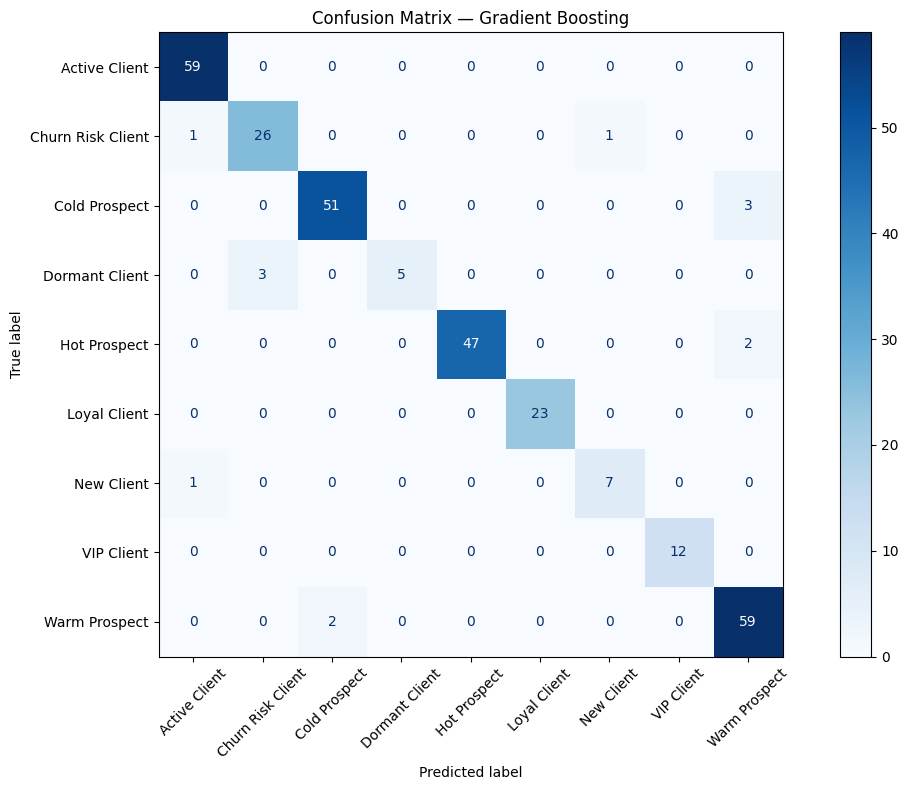

In [11]:
# ============================================================
# 11. Detailed evaluation of the best model
# ============================================================

best_pred = best_model.predict(X_test)

print("Best model:", best_model_name)
print("Accuracy:", round(accuracy_score(y_test, best_pred), 4))
print("F1 macro:", round(f1_score(y_test, best_pred, average="macro"), 4))
print("Recall macro:", round(recall_score(y_test, best_pred, average="macro"), 4))

report_dict = classification_report(
    y_test,
    best_pred,
    target_names=class_names,
    zero_division=0,
    output_dict=True,
)

report_df = pd.DataFrame(report_dict).T
display(report_df)

weak_classes = report_df.loc[
    [c for c in class_names if c in report_df.index],
    ["precision", "recall", "f1-score", "support"]
]

weak_classes = weak_classes[
    (weak_classes["recall"] < 0.60)
    | (weak_classes["f1-score"] < 0.60)
]

if len(weak_classes) > 0:
    print("⚠️ Warning: some classes are still weak.")
    display(weak_classes)
else:
    print("✅ No class has recall or F1-score below 0.60 on the test split.")

cm = confusion_matrix(y_test, best_pred)

fig, ax = plt.subplots(figsize=(12, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()


,feature,importance
17,conversion_probability,0.210980
18,churn_risk_score,0.138600
16,rfm_score,0.127125
23,rfm_frequency_score,0.120247
7,purchases_90d,0.106327
8,total_spent_90d_mad,0.105708
3,recency_days,0.063538
5,product_views_30d,0.055290
19,behavioral_engagement_score,0.019207
4,visits_30d,0.011930


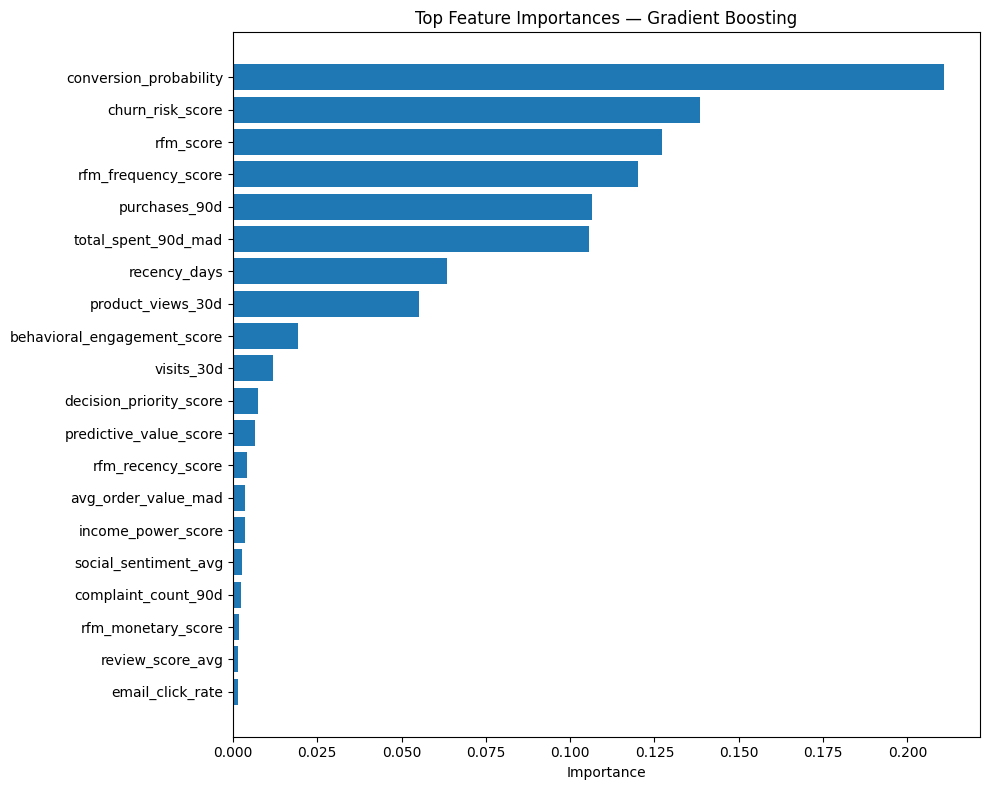

In [12]:
# ============================================================
# 12. Feature importance for tree-based best models
# ============================================================

def get_feature_names_from_preprocessor(preprocessor, numerical_cols, categorical_cols):
    feature_names = []
    feature_names.extend(numerical_cols)

    try:
        encoder = preprocessor.named_transformers_["cat"].named_steps["encoder"]
        cat_feature_names = encoder.get_feature_names_out(categorical_cols).tolist()
        feature_names.extend(cat_feature_names)
    except Exception:
        pass

    return feature_names

classifier = best_model.named_steps["classifier"]

if hasattr(classifier, "feature_importances_"):
    fitted_preprocessor = best_model.named_steps["preprocessor"]
    transformed_feature_names = get_feature_names_from_preprocessor(
        fitted_preprocessor,
        numerical_cols,
        categorical_cols
    )

    importances = classifier.feature_importances_

    importance_df = pd.DataFrame({
        "feature": transformed_feature_names[:len(importances)],
        "importance": importances,
    }).sort_values("importance", ascending=False)

    display(importance_df.head(30))

    plt.figure(figsize=(10, 8))
    top_imp = importance_df.head(20).sort_values("importance")
    plt.barh(top_imp["feature"], top_imp["importance"])
    plt.xlabel("Importance")
    plt.title(f"Top Feature Importances — {best_model_name}")
    plt.tight_layout()
    plt.show()
else:
    print("The selected classifier does not expose feature_importances_.")


In [13]:
# ============================================================
# 13. Clean manual test examples
# ============================================================

def build_manual_test_examples():
    base_profile = {
        "region": "Casablanca-Settat",
        "source_channel": "Organic SEO",
        "segment": "B2C",
        "persona": "Price Sensitive",
        "age_group": "25-34",
        "preferred_device": "Mobile",
        "preferred_category": "Fashion",
        "marketing_consent": True,
        "price_sensitivity": 0.50,
        "income_power_score": 0.50,
        "initial_interest_score": 0.50,
        "review_score_avg": np.nan,
        "social_mentions_30d": 0,
    }

    rows = []

    def add(name, expected, updates):
        row = base_profile.copy()
        row.update(updates)
        row["example"] = name
        row["expected_profile"] = expected
        rows.append(row)

    add("Cold Prospect Example", "Cold Prospect", {
        "entity_type": "Prospect", "recency_days": 90, "visits_30d": 1, "product_views_30d": 2,
        "cart_additions_30d": 0, "purchases_90d": 0, "total_spent_90d_mad": 0, "avg_order_value_mad": 0,
        "email_open_rate": 0.05, "email_click_rate": 0.00, "complaint_count_90d": 0,
        "social_sentiment_avg": 0.20, "conversion_probability": 0.05, "churn_risk_score": 0.00
    })

    add("Warm Prospect Example", "Warm Prospect", {
        "entity_type": "Prospect", "recency_days": 25, "visits_30d": 8, "product_views_30d": 25,
        "cart_additions_30d": 1, "purchases_90d": 0, "total_spent_90d_mad": 0, "avg_order_value_mad": 0,
        "email_open_rate": 0.35, "email_click_rate": 0.07, "complaint_count_90d": 0,
        "social_sentiment_avg": 0.60, "conversion_probability": 0.45, "churn_risk_score": 0.00
    })

    add("Hot Prospect Example", "Hot Prospect", {
        "entity_type": "Prospect", "recency_days": 3, "visits_30d": 28, "product_views_30d": 90,
        "cart_additions_30d": 8, "purchases_90d": 0, "total_spent_90d_mad": 0, "avg_order_value_mad": 0,
        "email_open_rate": 0.75, "email_click_rate": 0.30, "complaint_count_90d": 0,
        "social_sentiment_avg": 0.85, "conversion_probability": 0.90, "churn_risk_score": 0.00
    })

    add("New Client Example", "New Client", {
        "entity_type": "Client", "recency_days": 7, "visits_30d": 5, "product_views_30d": 18,
        "cart_additions_30d": 1, "purchases_90d": 1, "total_spent_90d_mad": 450, "avg_order_value_mad": 450,
        "email_open_rate": 0.30, "email_click_rate": 0.05, "complaint_count_90d": 0,
        "review_score_avg": 4.0, "social_sentiment_avg": 0.60, "conversion_probability": 1.00, "churn_risk_score": 0.15
    })

    add("Active Client Example", "Active Client", {
        "entity_type": "Client", "recency_days": 18, "visits_30d": 9, "product_views_30d": 30,
        "cart_additions_30d": 2, "purchases_90d": 4, "total_spent_90d_mad": 1800, "avg_order_value_mad": 450,
        "email_open_rate": 0.40, "email_click_rate": 0.08, "complaint_count_90d": 0,
        "review_score_avg": 4.1, "social_sentiment_avg": 0.65, "conversion_probability": 1.00, "churn_risk_score": 0.18
    })

    add("Loyal Client Example", "Loyal Client", {
        "entity_type": "Client", "recency_days": 10, "visits_30d": 14, "product_views_30d": 42,
        "cart_additions_30d": 4, "purchases_90d": 6, "total_spent_90d_mad": 3600, "avg_order_value_mad": 600,
        "email_open_rate": 0.55, "email_click_rate": 0.14, "complaint_count_90d": 0,
        "review_score_avg": 4.5, "social_sentiment_avg": 0.78, "conversion_probability": 1.00, "churn_risk_score": 0.12
    })

    add("VIP Client Example", "VIP Client", {
        "entity_type": "Client", "segment": "B2B", "persona": "B2B Decision Maker", "recency_days": 2,
        "visits_30d": 30, "product_views_30d": 100, "cart_additions_30d": 12, "purchases_90d": 10,
        "total_spent_90d_mad": 12000, "avg_order_value_mad": 1200, "email_open_rate": 0.80,
        "email_click_rate": 0.30, "complaint_count_90d": 0, "review_score_avg": 4.8,
        "social_mentions_30d": 8, "social_sentiment_avg": 0.90, "conversion_probability": 1.00, "churn_risk_score": 0.04
    })

    add("Dormant Client Example", "Dormant Client", {
        "entity_type": "Client", "recency_days": 105, "visits_30d": 2, "product_views_30d": 5,
        "cart_additions_30d": 0, "purchases_90d": 2, "total_spent_90d_mad": 700, "avg_order_value_mad": 350,
        "email_open_rate": 0.10, "email_click_rate": 0.01, "complaint_count_90d": 0,
        "review_score_avg": 3.5, "social_sentiment_avg": 0.45, "conversion_probability": 1.00, "churn_risk_score": 0.30
    })

    add("Churn Risk Client Example", "Churn Risk Client", {
        "entity_type": "Client", "recency_days": 70, "visits_30d": 3, "product_views_30d": 8,
        "cart_additions_30d": 0, "purchases_90d": 3, "total_spent_90d_mad": 1200, "avg_order_value_mad": 400,
        "email_open_rate": 0.08, "email_click_rate": 0.01, "complaint_count_90d": 3,
        "review_score_avg": 1.8, "social_mentions_30d": 3, "social_sentiment_avg": 0.10,
        "conversion_probability": 1.00, "churn_risk_score": 0.92
    })

    return pd.DataFrame(rows)

manual_examples_raw = build_manual_test_examples()

reference_for_scoring = df.drop(columns=["dynamic_class", "dynamic_class_original"], errors="ignore").copy()

manual_with_reference = pd.concat([
    reference_for_scoring,
    manual_examples_raw.drop(columns=["expected_profile", "example"], errors="ignore")
], ignore_index=True)

manual_with_reference = calculate_rfm_es(manual_with_reference)
manual_with_reference = update_derived_scores(manual_with_reference)

manual_scored = manual_with_reference.tail(len(manual_examples_raw)).copy()
manual_scored.index = manual_examples_raw["example"].values

manual_for_rules = pd.concat([
    df.drop(columns=["dynamic_class", "dynamic_class_original"], errors="ignore"),
    manual_scored
], ignore_index=True)

manual_rule_labeled = assign_dynamic_classes(manual_for_rules).tail(len(manual_examples_raw)).copy()

manual_scored["business_rule_class"] = manual_rule_labeled["dynamic_class"].values
manual_scored["expected_profile"] = manual_examples_raw["expected_profile"].values

manual_X = manual_scored[feature_columns].copy()

for col in categorical_cols:
    manual_X[col] = manual_X[col].fillna("Unknown").astype(str)

for col in numerical_cols:
    manual_X[col] = pd.to_numeric(manual_X[col], errors="coerce")

manual_pred_encoded = best_model.predict(manual_X)
manual_pred_labels = label_encoder.inverse_transform(manual_pred_encoded)

manual_results = pd.DataFrame({
    "example": manual_scored.index,
    "expected_profile": manual_scored["expected_profile"].values,
    "business_rule_class": manual_scored["business_rule_class"].values,
    "model_predicted_class": manual_pred_labels,
})

manual_results["matches_business_rule"] = (
    manual_results["business_rule_class"] == manual_results["model_predicted_class"]
)

display(manual_results)
print("Manual test match rate:", manual_results["matches_business_rule"].mean())


,example,expected_profile,business_rule_class,model_predicted_class,matches_business_rule
0,Cold Prospect Example,Cold Prospect,Cold Prospect,Cold Prospect,True
1,Warm Prospect Example,Warm Prospect,Warm Prospect,Warm Prospect,True
2,Hot Prospect Example,Hot Prospect,Hot Prospect,Hot Prospect,True
3,New Client Example,New Client,New Client,New Client,True
4,Active Client Example,Active Client,Active Client,Active Client,True
5,Loyal Client Example,Loyal Client,Loyal Client,Loyal Client,True
6,VIP Client Example,VIP Client,VIP Client,VIP Client,True
7,Dormant Client Example,Dormant Client,Dormant Client,Dormant Client,True
8,Churn Risk Client Example,Churn Risk Client,Dormant Client,Dormant Client,True


Manual test match rate: 1.0


In [14]:
# ============================================================
# 14. Save best model artifact for Streamlit
# ============================================================

ARTIFACT_PATH = Path("osmos_best_model_artifact.pkl")

model_artifact = {
    "model": best_model,
    "label_encoder": label_encoder,
    "feature_columns": feature_columns,
    "categorical_cols": categorical_cols,
    "numerical_cols": numerical_cols,
    "best_model_name": best_model_name,
    "selection_metric": SELECTION_METRIC,
    "results": results_df,
    "classification_report": report_df,
    "class_names": list(class_names),
    "entity_type_format": "string",
    "rfm_version": "RFM_ES_3_EXPERT_AHP",
    "ahp_result": {
        "criteria": ahp_result["criteria"],
        "weights": ahp_result["weights"],
        "CI": ahp_result["CI"],
        "CR": ahp_result["CR"],
        "expert_count": ahp_result["expert_count"],
        "aggregated_matrix": ahp_result["aggregated_matrix"],
    },
    "target_generation": target_generation,
    "business_rule_labeling": "quantile_based_dynamic_class_after_rfm_es",
    "safety_rule_classes": ["New Client", "Dormant Client"],
    "feature_defaults": DEFAULTS,
    "data_file_used": str(DATA_FILE_USED),
    "export_date": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
}

joblib.dump(model_artifact, ARTIFACT_PATH)

print("✅ Best model saved:", best_model_name)
print("✅ Artifact saved as:", ARTIFACT_PATH.resolve())
print("✅ Entity type format:", model_artifact["entity_type_format"])
print("✅ RFM version:", model_artifact["rfm_version"])


✅ Best model saved: Gradient Boosting
✅ Artifact saved as: /mnt/data/osmos_best_model_artifact.pkl
✅ Entity type format: string
✅ RFM version: RFM_ES_3_EXPERT_AHP


## Streamlit compatibility note

Before using this exported artifact in the interface, update `predict_class()`:

```python
entity_type_format = model_artifact.get("entity_type_format", "string")

if entity_type_format == "string":
    # Keep values as "Prospect" / "Client"
    # Do NOT convert to 0 / 1
else:
    # Only use numeric encoding if the artifact explicitly requires it.
```

This is the most important interface change after this notebook fix.